ACQUAINTANCES CONSPIRACY SCORES



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   author            667 non-null    object 
 1   subreddits        667 non-null    object 
 2   conspiracy_score  667 non-null    float64
dtypes: float64(1), object(2)
memory usage: 15.8+ KB
None


         author                                         subreddits  \
0     geiger253  [{'subreddit': 'reddit.com', 'count': 335}, {'...   
1      morituri  [{'subreddit': 'reddit.com', 'count': 95}, {'s...   
2  downdiagonal  [{'subreddit': 'reddit.com', 'count': 3}, {'su...   
3   jaggederest  [{'subreddit': 'reddit.com', 'count': 1847}, {...   
4     otakucode  [{'subreddit': 'reddit.com', 'count': 2814}, {...   

   conspiracy_score  
0         -0.101575  
1         -0.030149  
2         -0.204984  
3         -0.192808  
4         -0.141335  


           author                           

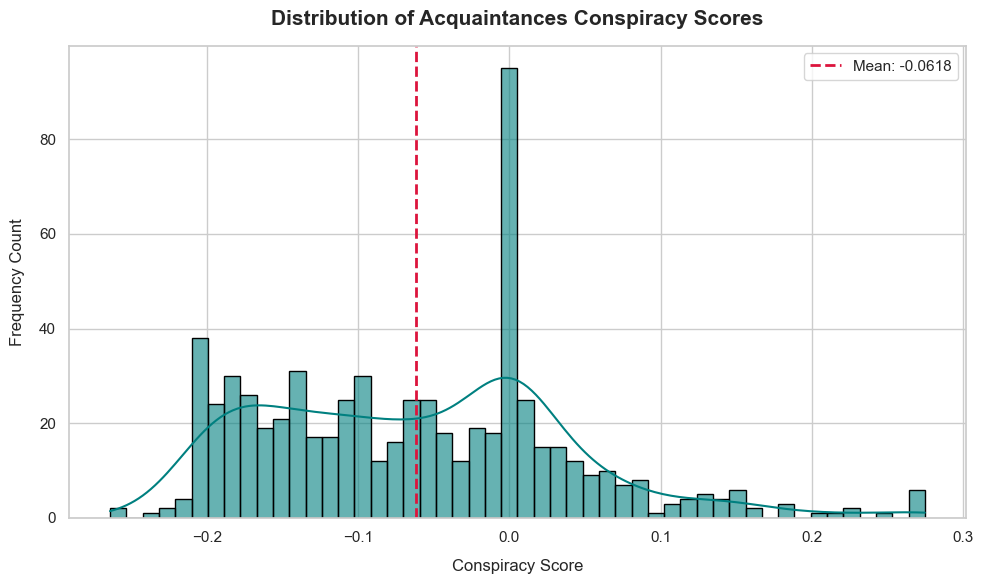

In [6]:
import pandas as pd
import matplotlib.pyplot as plt  # Corretto l'import per pyplot
import seaborn as sns
import json
import numpy as np
import os


founders_folder_path = "../data/raw/FOUNDERS_DATA/"

matching_dict_path = "../data/interim/matching_dict_optimized.json"
with open(matching_dict_path, "r") as f:
    matching_dict = json.load(f)
    
# Collect founder usernames
anchors = [anchor for anchor in matching_dict.keys()]
candidates = [candidate["candidate"] for candidate in matching_dict.values()]
founders = anchors + candidates

dfs = list()

for f in founders:
    founder_path = f + "_data/"
    acquaintances_scores_path = f + "_acquaintancesScores.csv"

    full_path = os.path.join(founders_folder_path, founder_path, acquaintances_scores_path)

    if os.path.exists(full_path):
        df = pd.read_csv(full_path)
        dfs.append(df)

df_complete = pd.concat(dfs, ignore_index=True)

print("\n")
print(df_complete.info())
print("\n")
print(df_complete.head(5))
print("\n")
print(df_complete.tail(5))
print("\n")


# ==============================================================================
# Acquaintances Conspiracy Scores Distribution Plot
# ==============================================================================

# Imposta il tema grafico di Seaborn per una resa accademica pulita
sns.set_theme(style="whitegrid")

# Inizializza la figura
plt.figure(figsize=(10, 6))

# Genera l'istogramma con la curva di densità (KDE) sovrapposta
sns.histplot(
    data=df_complete,
    x="conspiracy_score",
    kde=True,
    bins=50,
    color="teal",
    edgecolor="black",
    alpha=0.6
)

# Calcola e aggiunge la linea verticale della media per dare un punto di riferimento
mean_score = df_complete["conspiracy_score"].mean()
plt.axvline(
    x=mean_score,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_score:.4f}"
)

# Ottimizzazione di etichette e titoli
plt.title("Distribution of Acquaintances Conspiracy Scores", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Conspiracy Score", fontsize=12, labelpad=10)
plt.ylabel("Frequency Count", fontsize=12, labelpad=10)
plt.legend(fontsize=11, loc="upper right")

# Rende il layout compatto eliminando i margini vuoti in eccesso
plt.tight_layout()

# Mostra il grafico a schermo
plt.show()
